# Hyper-parameter search (logged results)

The previous version of this notebook declared a 960-configuration x 4-fold MLP grid that was never run.
The search that was actually executed is **sequential one-factor sweeps selected on the validation split**
(`uv run python -m src tune --model all`, see `src/experiments/search.py`). This notebook only displays the
logs in `results/tuning/*.json`: every configuration that was evaluated, in order, with its cost.

In [1]:
import sys
from pathlib import Path

# make `src` importable whether the notebook is opened from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
from IPython.display import Image, display

from src.experiments.search import CLASS_NAME, SPECS

tuning = {m: json.loads((ROOT / "results" / "tuning" / f"{CLASS_NAME[m]}.json").read_text()) for m in SPECS}
pd.DataFrame([{"model": CLASS_NAME[m], "configurations evaluated": t["n_trials"], "best validation accuracy": t["best_val_acc"],
               "selected": t["best_params"]} for m, t in tuning.items()]).set_index("model")

,configurations evaluated,best validation accuracy,selected
model,,,
GaussianNB,12,0.7967,{'var_smoothing': 0.1}
SoftmaxRegression,16,0.9215,"{'learning_rate': 0.03, 'l2': 0.0, 'epochs': 6..."
MLP,22,0.9818,"{'hidden_sizes': [512, 256], 'learning_rate': ..."
AdaBoostSAMME,14,0.9759,"{'n_estimators': 393, 'max_depth': 10, 'learni..."


## Every evaluated configuration

In [2]:
for m, t in tuning.items():
    print("\n==", CLASS_NAME[m], "==")
    df = pd.DataFrame([{"stage": r["stage"], "value": r["value"], "train_acc": r["train_acc"], "val_acc": r["val_acc"], "fit_s": r["train_time_sec"]}
                       for r in t["trials"]])
    display(df.style.format({"train_acc": "{:.4f}", "val_acc": "{:.4f}", "fit_s": "{:.1f}"}))


== GaussianNB ==


,stage,value,train_acc,val_acc,fit_s
0,sweep:var_smoothing,0.000000,0.5660,0.5605,0.4
1,sweep:var_smoothing,0.000000,0.5801,0.5783,0.4
2,sweep:var_smoothing,0.000000,0.5974,0.5956,0.6
3,sweep:var_smoothing,0.000001,0.6193,0.6210,0.4
4,sweep:var_smoothing,0.000010,0.6471,0.6500,0.4
5,sweep:var_smoothing,0.000100,0.6866,0.6843,0.4
6,sweep:var_smoothing,0.001000,0.7347,0.7345,0.4
7,sweep:var_smoothing,0.010000,0.7798,0.7795,0.4
8,sweep:var_smoothing,0.030000,0.7970,0.7920,0.3
9,sweep:var_smoothing,0.100000,0.8013,0.7967,0.4



== SoftmaxRegression ==


,stage,value,train_acc,val_acc,fit_s
0,sweep:learning_rate,0.003000,0.9174,0.9124,5.5
1,sweep:learning_rate,0.010000,0.9271,0.9166,5.4
2,sweep:learning_rate,0.030000,0.9314,0.9172,5.8
3,sweep:learning_rate,0.100000,0.9278,0.9107,5.5
4,sweep:learning_rate,0.300000,0.9051,0.8871,5.3
5,sweep:learning_rate,1.000000,0.8972,0.8803,5.2
6,sweep:batch_size,16.000000,0.9200,0.9023,8.2
7,sweep:batch_size,32.000000,0.9290,0.9119,7.0
8,sweep:batch_size,64.000000,0.9321,0.9169,6.3
9,sweep:batch_size,256.000000,0.9283,0.9163,6.0



== MLP ==


,stage,value,train_acc,val_acc,fit_s
0,sweep:hidden_sizes,[32],0.9773,0.9565,2.0
1,sweep:hidden_sizes,[64],0.9781,0.9646,1.2
2,sweep:hidden_sizes,[128],0.9925,0.9748,2.1
3,sweep:hidden_sizes,[256],0.9973,0.9790,3.5
4,sweep:hidden_sizes,[512],0.9981,0.9794,5.7
5,sweep:hidden_sizes,"[256, 128]",0.9924,0.9760,5.1
6,sweep:hidden_sizes,"[512, 256]",0.9987,0.9818,53.1
7,sweep:hidden_sizes,"[512, 256, 128]",0.9897,0.9715,6.9
8,sweep:learning_rate,0.005000,0.9983,0.9763,15.4
9,sweep:learning_rate,0.010000,0.9982,0.9771,15.6



== AdaBoostSAMME ==


,stage,value,train_acc,val_acc,fit_s
0,sweep:max_depth,2.000000,0.7752,0.7723,7.4
1,sweep:max_depth,4.000000,0.8943,0.8876,15.4
2,sweep:max_depth,6.000000,0.9571,0.9225,30.4
3,sweep:max_depth,8.000000,0.9935,0.9480,68.2
4,sweep:max_depth,10.000000,0.9999,0.9598,191.6
5,sweep:max_features,0.250000,0.9996,0.9603,49.1
6,sweep:max_features,0.500000,0.9999,0.9629,97.6
7,sweep:learning_rate,0.100000,0.9998,0.9702,110.0
8,sweep:learning_rate,0.300000,1.0000,0.9684,111.7
9,sweep:learning_rate,0.500000,1.0000,0.9699,104.1


## One-factor sweep plots (train vs validation)

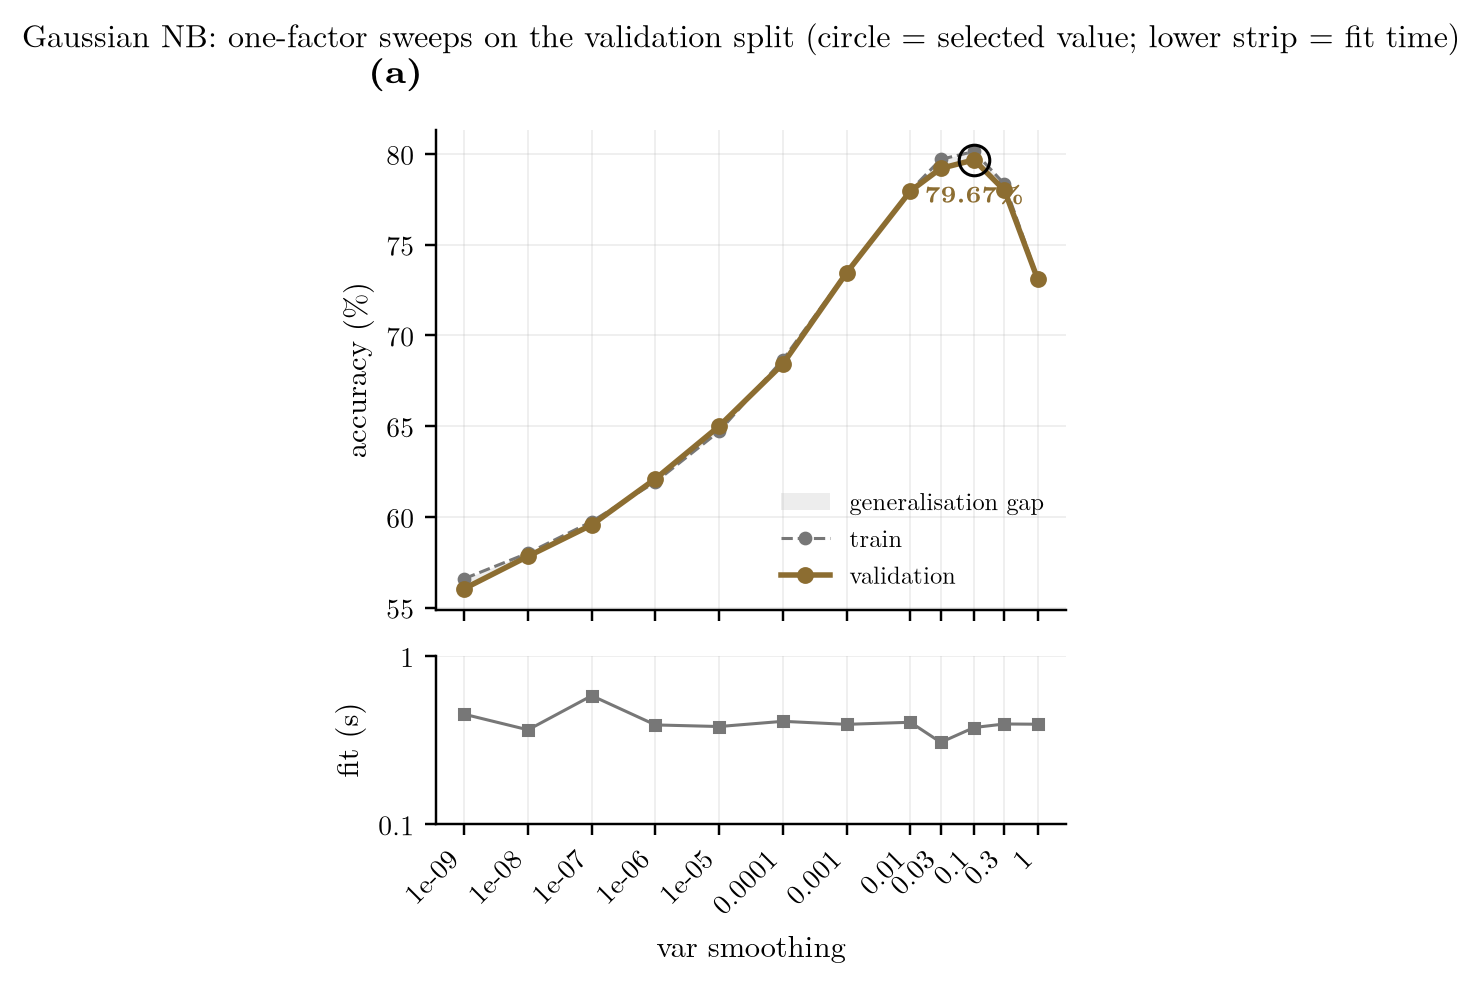

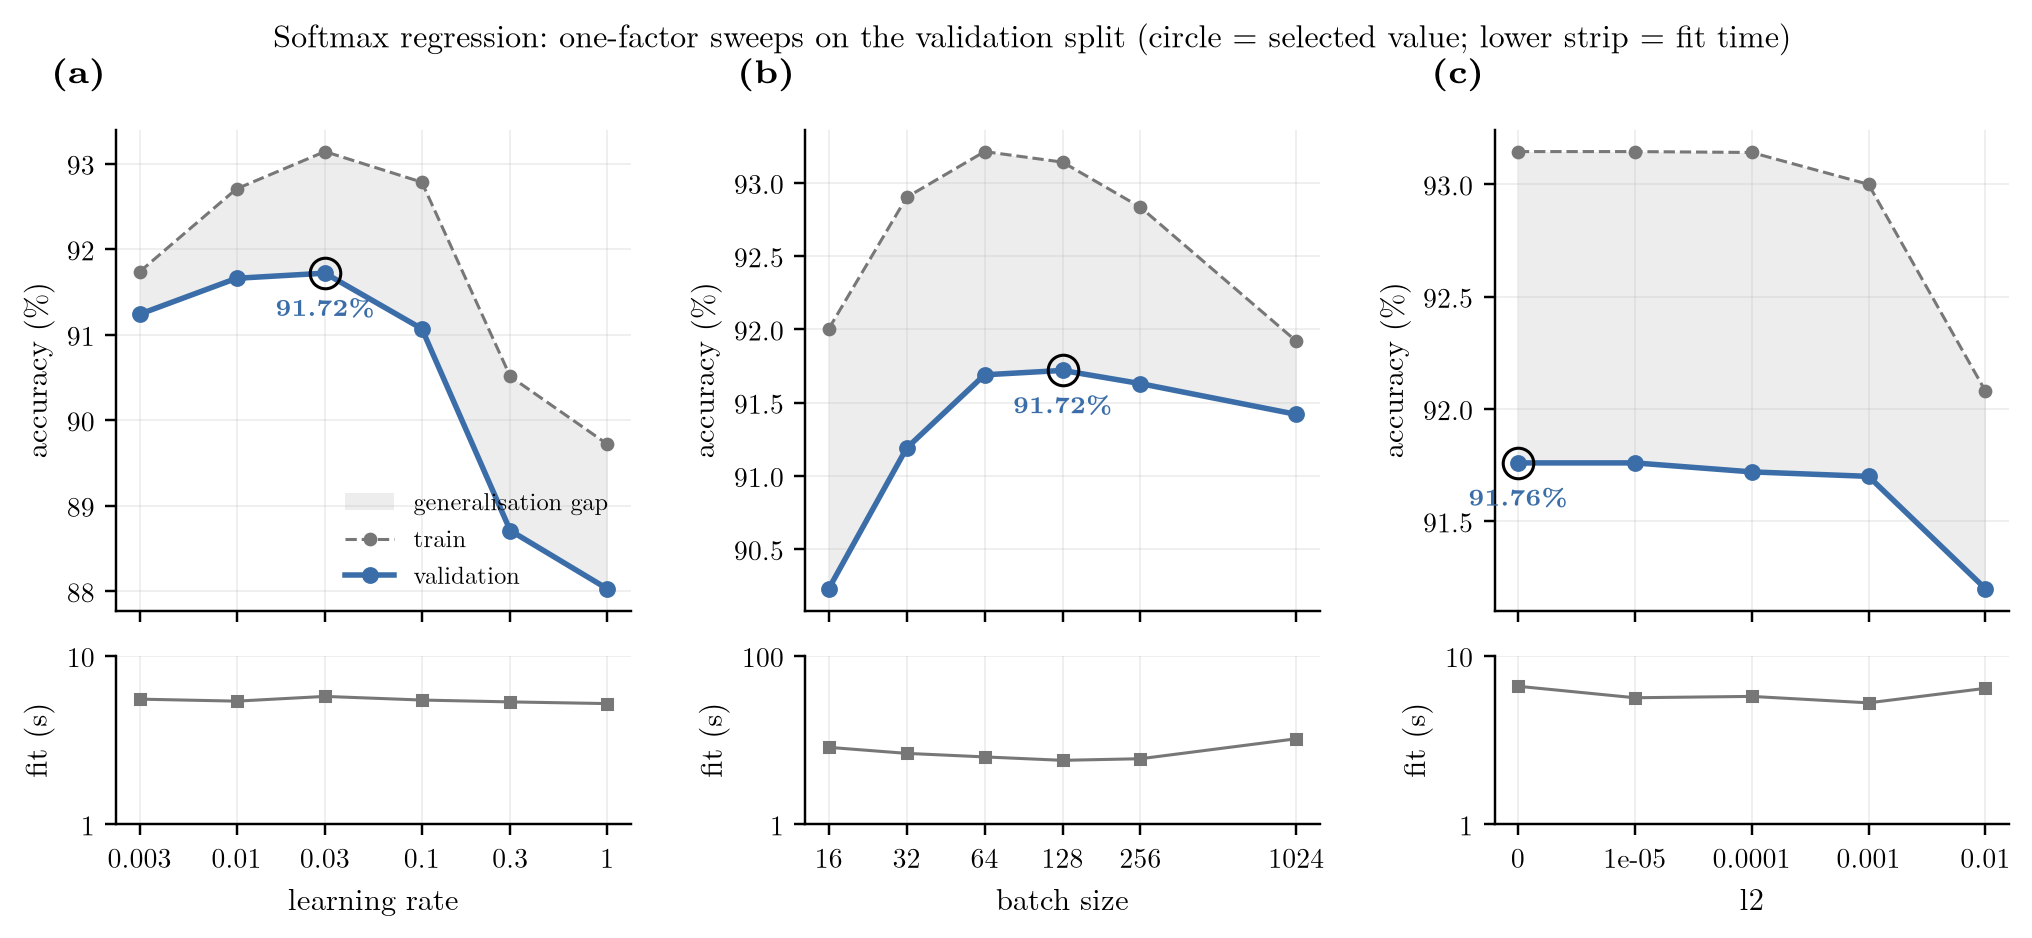

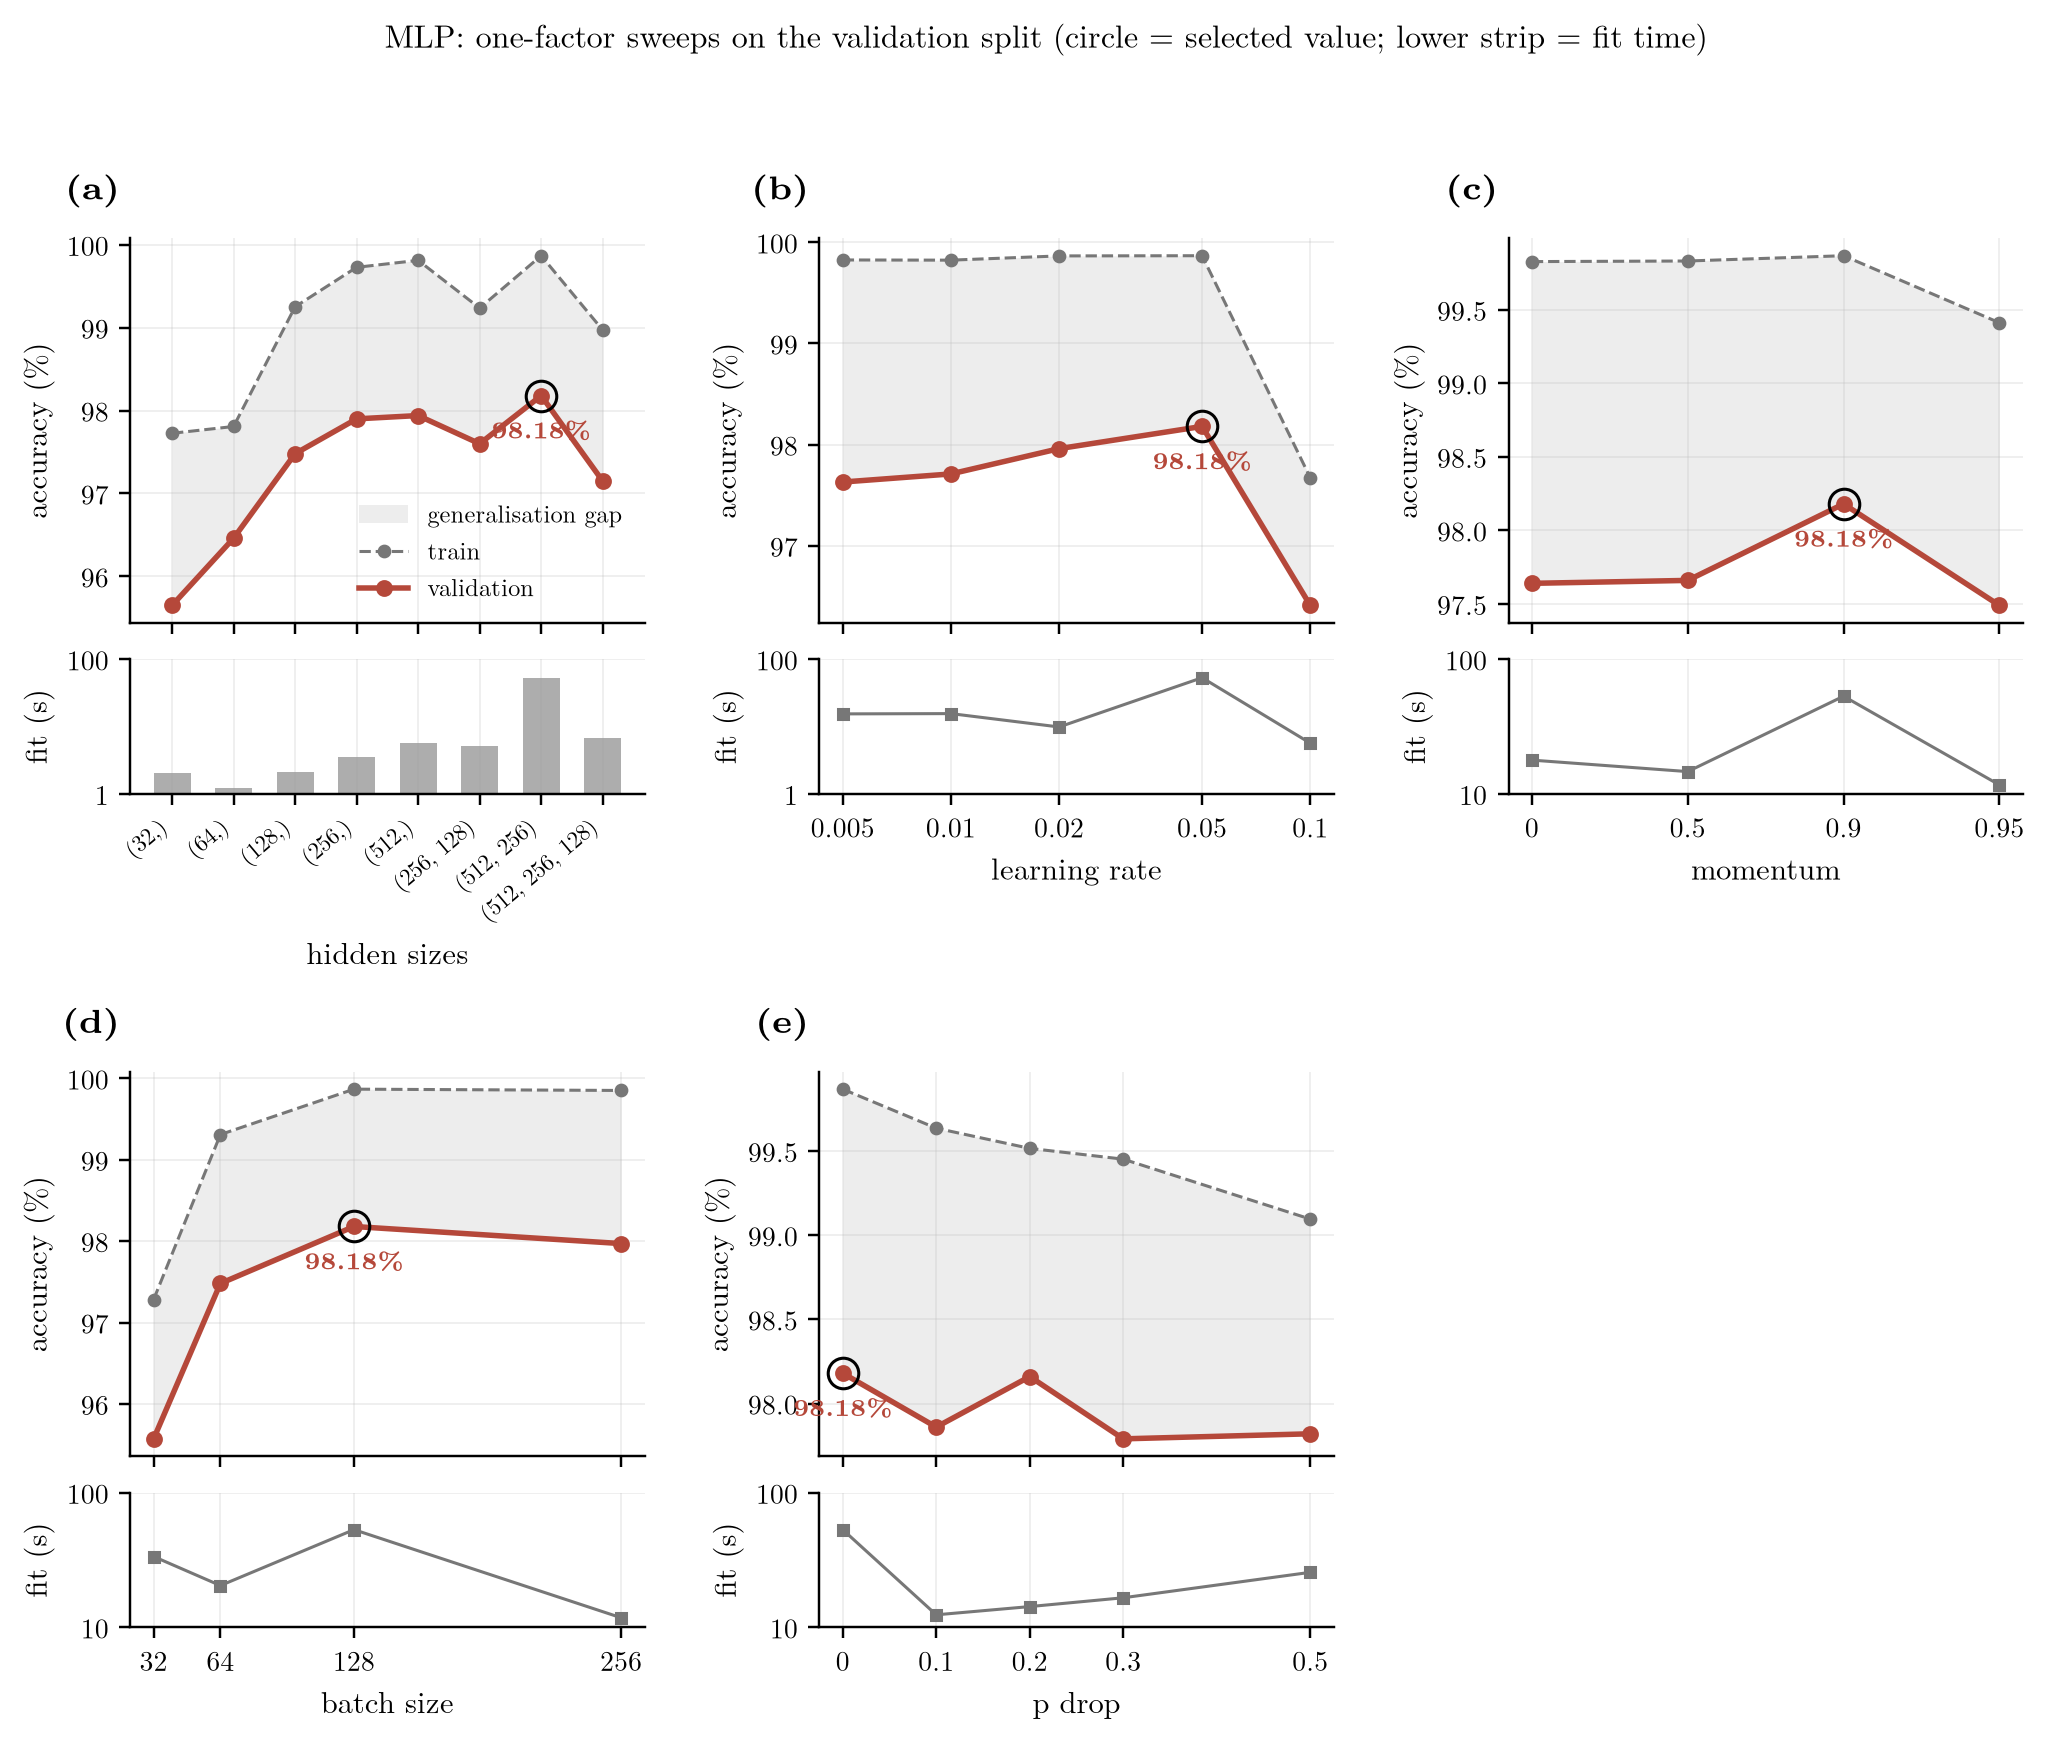

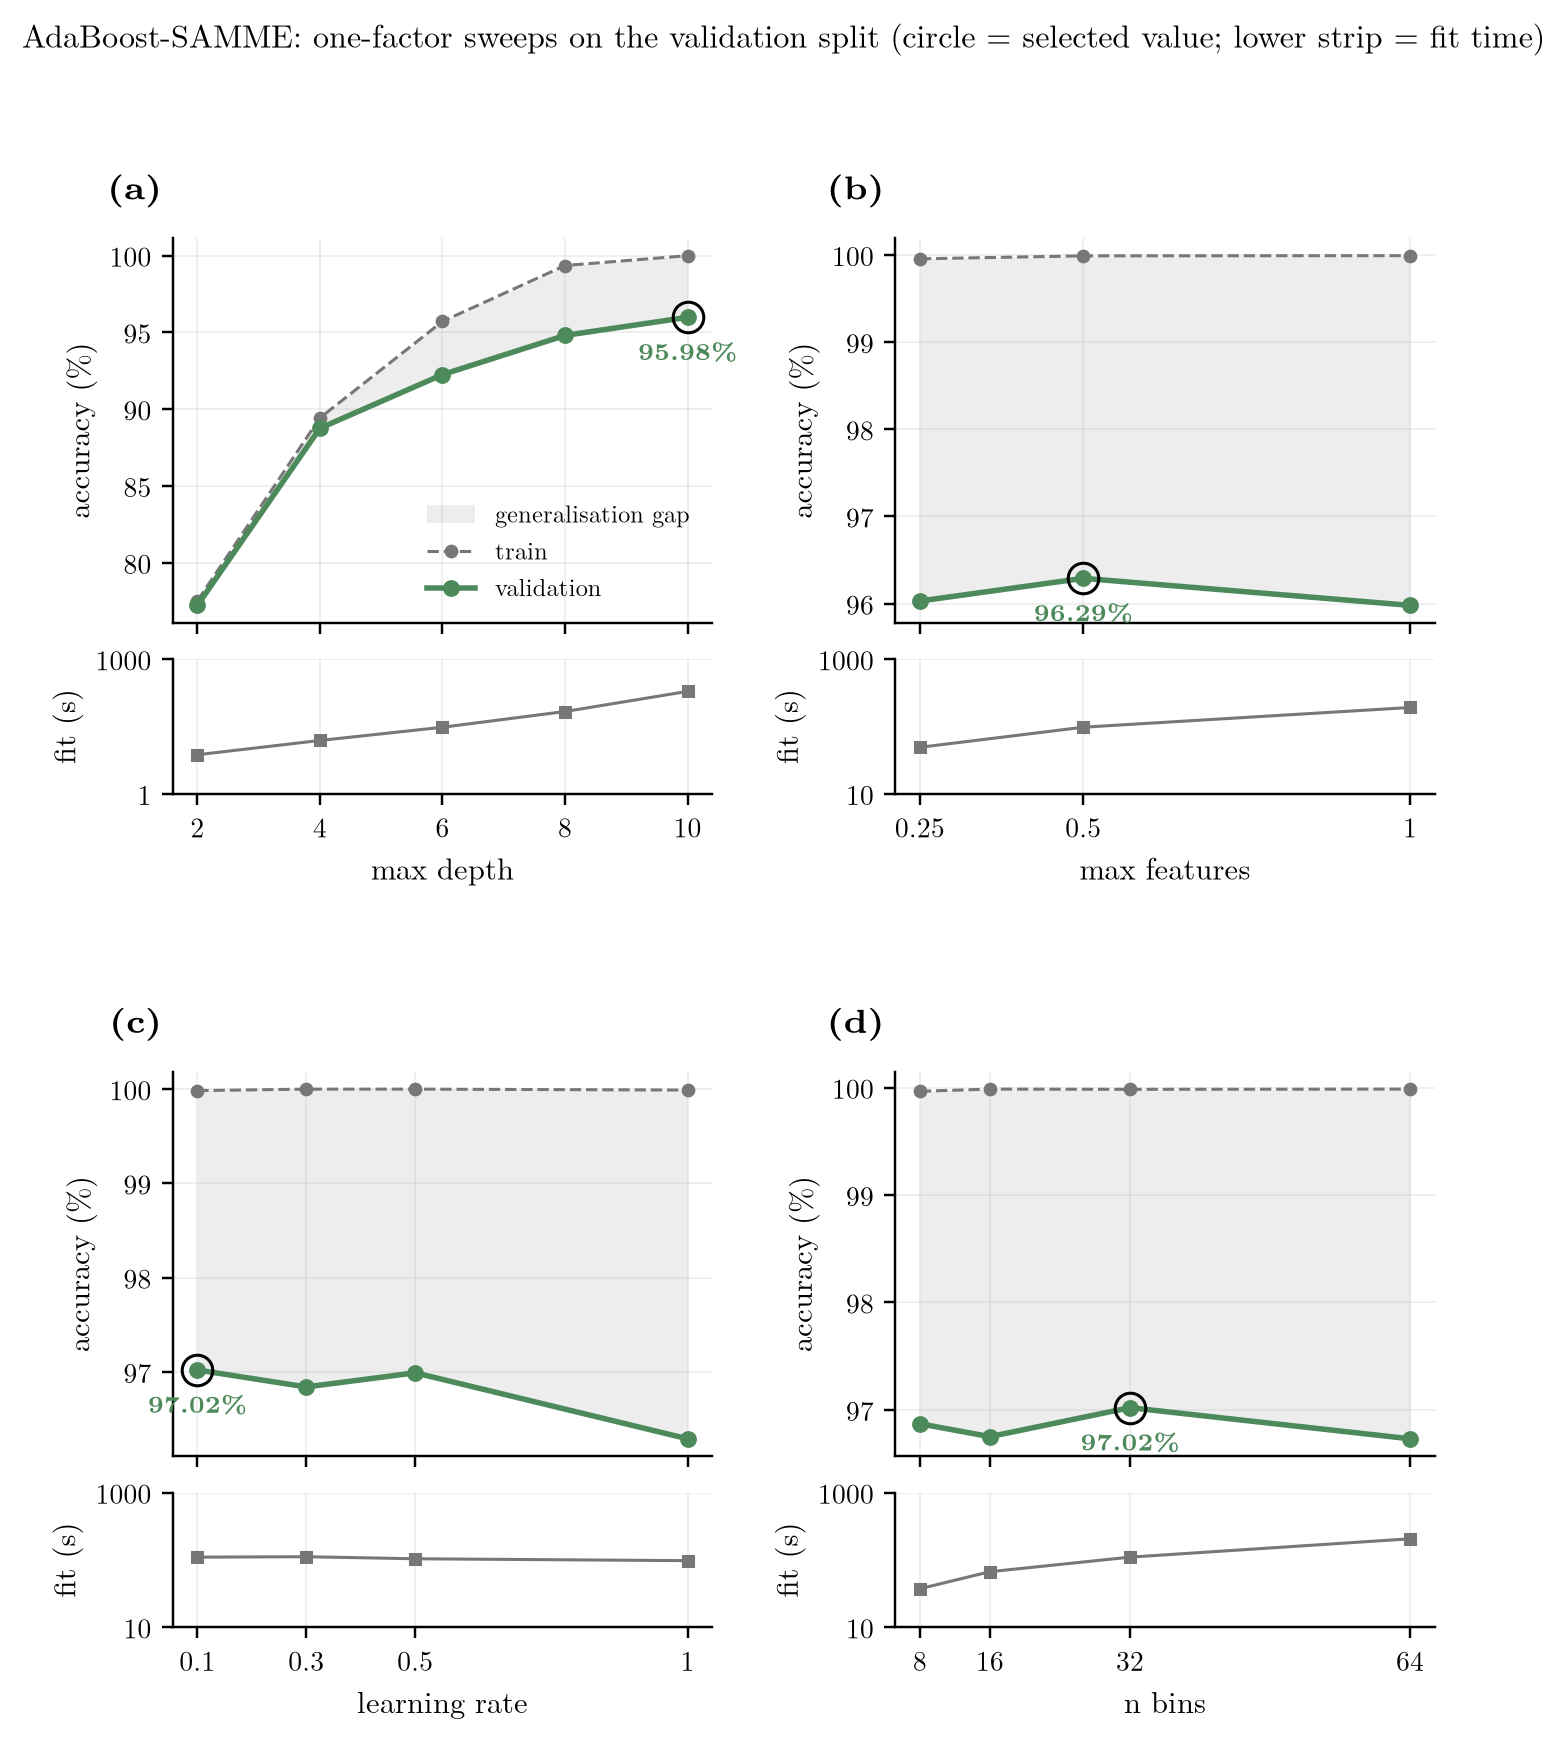

In [3]:
for m in SPECS:
    display(Image(str(ROOT / "results" / "figures" / f"sweep_{m}.png")))

## Learning curves of the final models

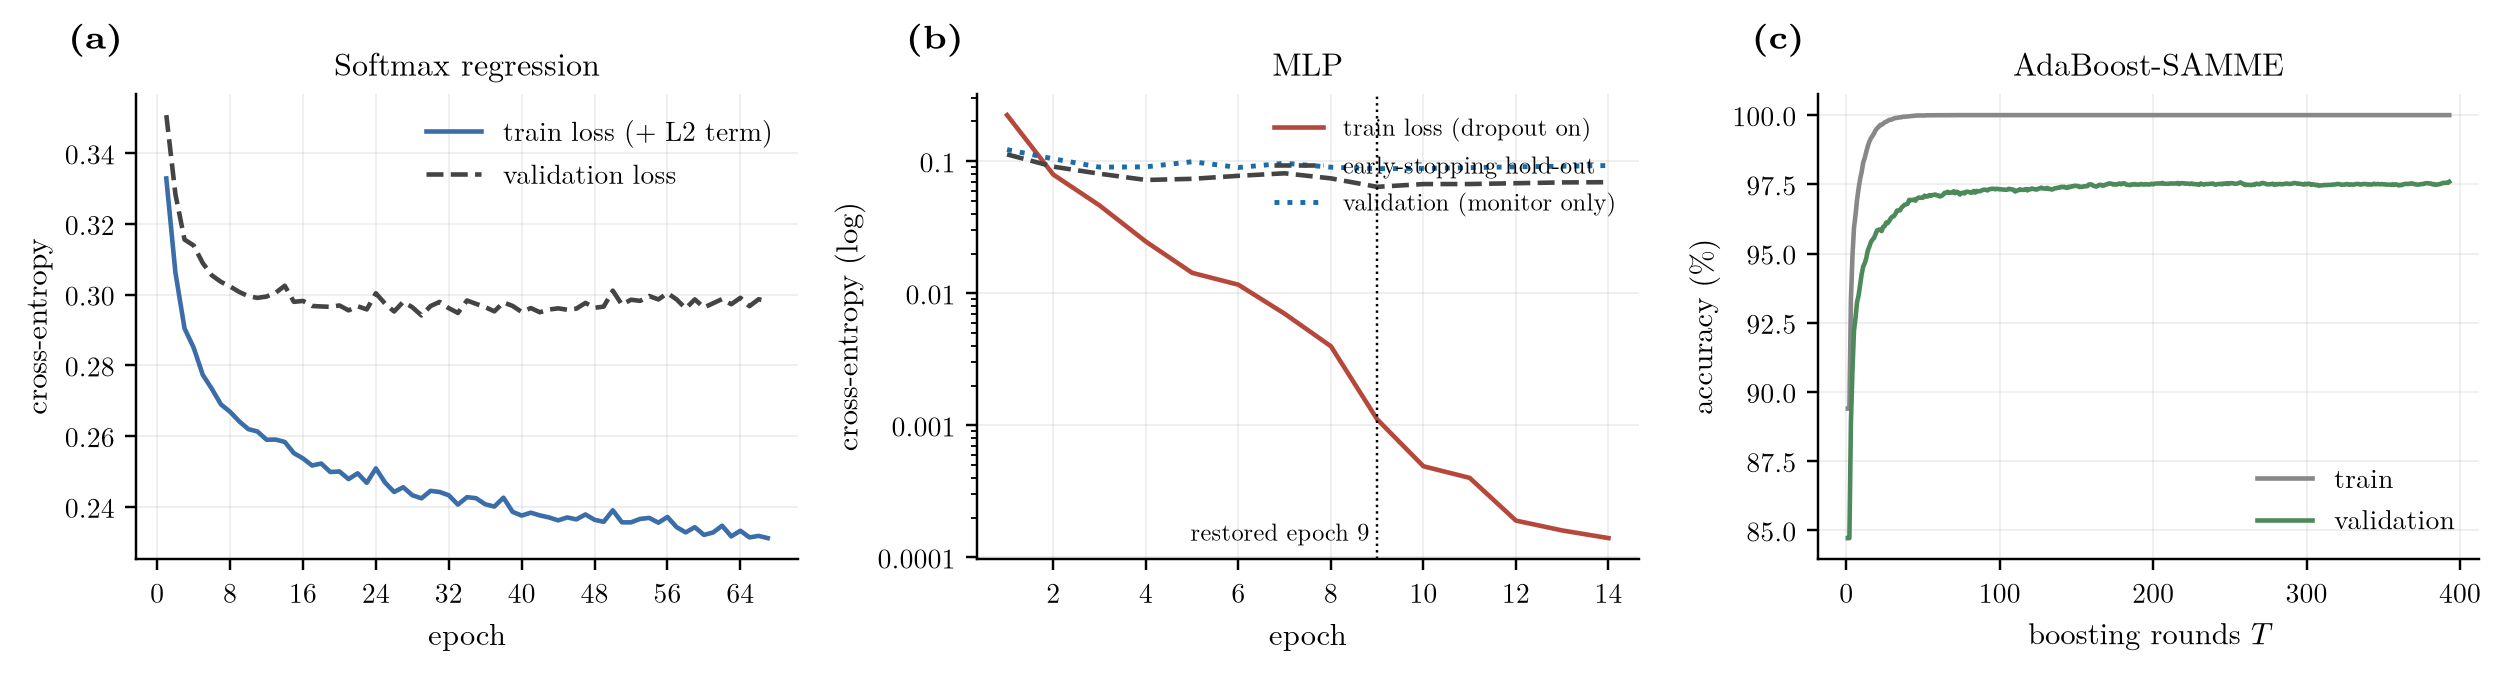

In [4]:
display(Image(str(ROOT / "results" / "figures" / "learning_curves.png")))